<a href="https://colab.research.google.com/github/DinaraAntropova/MachineLearning_2/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%BD%D0%B0_3_%D0%9D%D0%B5%D0%B9%D1%80%D0%BE%D0%BD%D0%BD%D1%96_%D0%BC%D0%B5%D1%80%D0%B5%D0%B6%D1%96_%D0%92%D0%B0%D1%80%D1%96%D0%B0%D0%BD%D1%82_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Навчальна вибірка (варіант №2)
X = np.array([
    [0.7, 0.6, -0.4],
    [0.3, -1.1, 0.7],
    [-1.2, 0.9, 1.4],
    [0.1, 1.3, -0.5],
    [-0.8, -1.4, 0.2],
    [-0.3, 0.2, 0.6],
    [-0.5, 0.6, -1.3]
])

# Початкова вагова матриця
W = np.array([
    [0.2, 0.3, -0.2],
    [0.1, -0.4, 0.3],
    [-0.3, 0.2, 0.4]
])

# Параметри навчання
k = 0.4
n_clusters = 3

print("Навчальна вибірка:")
print(X)

print("\nПочаткова вагова матриця:")
print(W)

print("\nНорма навчання:", k)
print("Кількість кластерів:", n_clusters)


Навчальна вибірка:
[[ 0.7  0.6 -0.4]
 [ 0.3 -1.1  0.7]
 [-1.2  0.9  1.4]
 [ 0.1  1.3 -0.5]
 [-0.8 -1.4  0.2]
 [-0.3  0.2  0.6]
 [-0.5  0.6 -1.3]]

Початкова вагова матриця:
[[ 0.2  0.3 -0.2]
 [ 0.1 -0.4  0.3]
 [-0.3  0.2  0.4]]

Норма навчання: 0.4
Кількість кластерів: 3


In [2]:

# Навчання мережі Кохонена (перша епоха)

W_train = W.copy()

for i, x in enumerate(X):
    # Обчислення евклідових відстаней
    distances = np.linalg.norm(W_train - x, axis=1)

    # Пошук найближчого нейрона
    winner = np.argmin(distances)

    # Оновлення ваг нейрона-переможця
    W_train[winner] = W_train[winner] + k * (
        x - W_train[winner]
    )

    print(f"Вектор X{i+1}: {x}")
    print("Відстані:", np.round(distances, 3))
    print(f"Нейрон-переможець: {winner+1}")
    print("Оновлені ваги:",
          np.round(W_train[winner], 3))
    print("-----------------------------")

print("\nВагова матриця після першої епохи:")
print(np.round(W_train, 3))



Вектор X1: [ 0.7  0.6 -0.4]
Відстані: [0.616 1.36  1.342]
Нейрон-переможець: 1
Оновлені ваги: [ 0.4   0.42 -0.28]
-----------------------------
Вектор X2: [ 0.3 -1.1  0.7]
Відстані: [1.811 0.831 1.463]
Нейрон-переможець: 2
Оновлені ваги: [ 0.18 -0.68  0.46]
-----------------------------
Вектор X3: [-1.2  0.9  1.4]
Відстані: [2.369 2.299 1.517]
Нейрон-переможець: 3
Оновлені ваги: [-0.66  0.48  0.8 ]
-----------------------------
Вектор X4: [ 0.1  1.3 -0.5]
Відстані: [0.955 2.202 1.715]
Нейрон-переможець: 1
Оновлені ваги: [ 0.28   0.772 -0.368]
-----------------------------
Вектор X5: [-0.8 -1.4  0.2]
Відстані: [2.491 1.244 1.978]
Нейрон-переможець: 2
Оновлені ваги: [-0.212 -0.968  0.356]
-----------------------------
Вектор X6: [-0.3  0.2  0.6]
Відстані: [1.265 1.196 0.498]
Нейрон-переможець: 3
Оновлені ваги: [-0.516  0.368  0.72 ]
-----------------------------
Вектор X7: [-0.5  0.6 -1.3]
Відстані: [1.227 2.299 2.033]
Нейрон-переможець: 1
Оновлені ваги: [-0.032  0.703 -0.741]
----------

In [3]:


# Продовження навчання мережі Кохонена

W_final = W_train.copy()

for epoch in range(2, 101):
    W_old = W_final.copy()

    for x in X:
        # Обчислення відстаней
        distances = np.linalg.norm(W_final - x, axis=1)

        # Визначення найближчого нейрона
        winner = np.argmin(distances)

        # Оновлення ваг
        W_final[winner] += k * (x - W_final[winner])

    # Перевірка зміни ваг
    change = np.max(np.abs(W_final - W_old))

    if change < 1e-6:
        break

print("Кількість епох навчання:", epoch)

print("\nКінцева вагова матриця:")
print(np.round(W_final, 4))

# Визначення кластерів
print("\nРозподіл векторів за кластерами:")

clusters = []

for i, x in enumerate(X):
    distances = np.linalg.norm(W_final - x, axis=1)
    cluster = np.argmin(distances) + 1
    clusters.append(cluster)

    print(f"X{i+1} -> Кластер {cluster}")

# Таблиця результатів
results = pd.DataFrame({
    "Вектор": [f"X{i+1}" for i in range(len(X))],
    "Кластер": clusters
})

display(results)


Кількість епох навчання: 14

Кінцева вагова матриця:
[[-0.0959  0.8143 -0.8898]
 [-0.3875 -1.2875  0.3875]
 [-0.6375  0.4625  0.9   ]]

Розподіл векторів за кластерами:
X1 -> Кластер 1
X2 -> Кластер 2
X3 -> Кластер 3
X4 -> Кластер 1
X5 -> Кластер 2
X6 -> Кластер 3
X7 -> Кластер 1


,Вектор,Кластер
0,X1,1
1,X2,2
2,X3,3
3,X4,1
4,X5,2
5,X6,3
6,X7,1


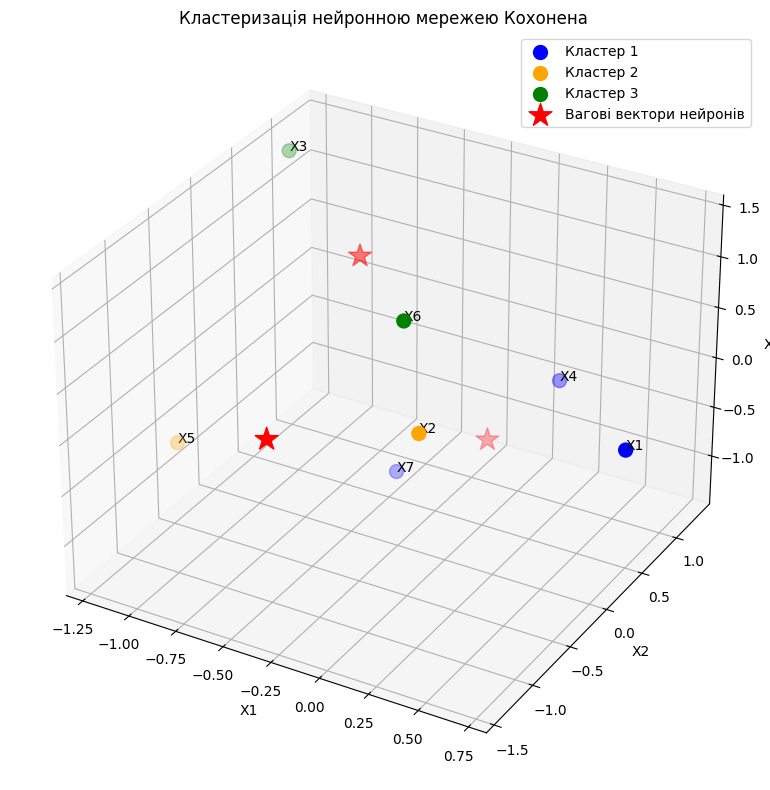

In [4]:

from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np

# Створення тривимірного графіка
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

colors = ["blue", "orange", "green"]

# Відображення кластерів
for cluster in range(1, 4):
    points = X[np.array(clusters) == cluster]

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=colors[cluster-1],
        s=100,
        label=f"Кластер {cluster}"
    )

# Підписи точок
for i, point in enumerate(X):
    ax.text(
        point[0],
        point[1],
        point[2],
        f"X{i+1}",
        fontsize=10
    )

# Відображення кінцевих ваг нейронів
ax.scatter(
    W_final[:, 0],
    W_final[:, 1],
    W_final[:, 2],
    color="red",
    marker="*",
    s=300,
    label="Вагові вектори нейронів"
)

# Назви осей
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X3")

ax.set_title("Кластеризація нейронною мережею Кохонена")
ax.legend()

plt.tight_layout()

# Збереження графіка
plt.savefig("kohonen_clusters.png", dpi=200)

plt.show()


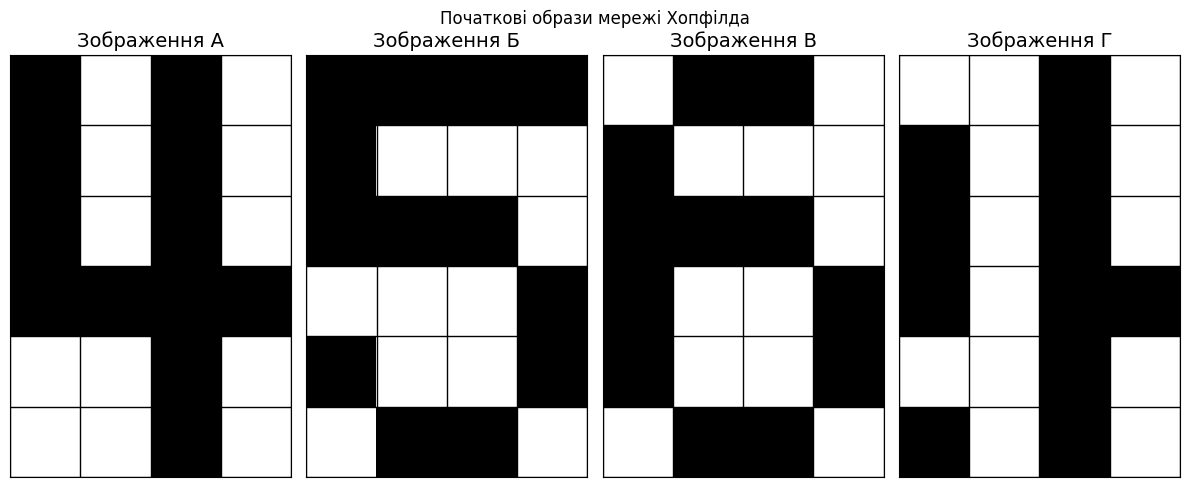

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Зображення А
A = np.array([
    [1, 0, 1, 0],
    [1, 0, 1, 0],
    [1, 0, 1, 0],
    [1, 1, 1, 1],
    [0, 0, 1, 0],
    [0, 0, 1, 0]
])

# Зображення Б
B = np.array([
    [1, 1, 1, 1],
    [1, 0, 0, 0],
    [1, 1, 1, 0],
    [0, 0, 0, 1],
    [1, 0, 0, 1],
    [0, 1, 1, 0]
])

# Зображення В
V = np.array([
    [0, 1, 1, 0],
    [1, 0, 0, 0],
    [1, 1, 1, 0],
    [1, 0, 0, 1],
    [1, 0, 0, 1],
    [0, 1, 1, 0]
])

# Зображення Г (потрібно відновити)
G = np.array([
    [0, 0, 1, 0],
    [1, 0, 1, 0],
    [1, 0, 1, 0],
    [1, 0, 1, 1],
    [0, 0, 1, 0],
    [1, 0, 1, 0]
])

# Візуалізація зображень
patterns = [A, B, V, G]
names = ["А", "Б", "В", "Г"]

fig, axes = plt.subplots(1, 4, figsize=(12, 5))

for ax, pattern, name in zip(axes, patterns, names):
    ax.imshow(pattern, cmap="Greys", vmin=0, vmax=1)

    ax.set_title(f"Зображення {name}", fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 6, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=1)
    ax.tick_params(which="minor", length=0)

plt.suptitle("Початкові образи мережі Хопфілда")
plt.tight_layout()
plt.show()


In [6]:

# Підготовка навчальних образів
patterns = np.array([A, B, V])

# Перетворення 0 -> -1, 1 -> +1
bipolar_patterns = patterns.reshape(3, 24) * 2 - 1

print("Біполярні вектори:")
print(bipolar_patterns)

# Побудова вагової матриці мережі Хопфілда
W_hopfield = (
    bipolar_patterns.T @ bipolar_patterns
) / 24

# Нульова головна діагональ
np.fill_diagonal(W_hopfield, 0)

print("\nРозмір вагової матриці:")
print(W_hopfield.shape)

print("\nПерші 5 рядків і 5 стовпців матриці:")
print(np.round(W_hopfield[:5, :5], 3))

print("\nЧи симетрична матриця?")
print(np.allclose(W_hopfield, W_hopfield.T))


Біполярні вектори:
[[ 1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1  1  1  1 -1 -1  1 -1 -1 -1  1 -1]
 [ 1  1  1  1  1 -1 -1 -1  1  1  1 -1 -1 -1 -1  1  1 -1 -1  1 -1  1  1 -1]
 [-1  1  1 -1  1 -1 -1 -1  1  1  1 -1  1 -1 -1  1  1 -1 -1  1 -1  1  1 -1]]

Розмір вагової матриці:
(24, 24)

Перші 5 рядків і 5 стовпців матриці:
[[ 0.    -0.042  0.042  0.042  0.042]
 [-0.042  0.     0.042  0.042  0.042]
 [ 0.042  0.042  0.    -0.042  0.125]
 [ 0.042  0.042 -0.042  0.    -0.042]
 [ 0.042  0.042  0.125 -0.042  0.   ]]

Чи симетрична матриця?
True


Початковий образ Г:
[[0 0 1 0]
 [1 0 1 0]
 [1 0 1 0]
 [1 0 1 1]
 [0 0 1 0]
 [1 0 1 0]]
Ітерація 1: змінено клітинок = 3
Ітерація 2: змінено клітинок = 0

Відновлене зображення:
[[1 0 1 0]
 [1 0 1 0]
 [1 0 1 0]
 [1 1 1 1]
 [0 0 1 0]
 [0 0 1 0]]

Чи збігається результат із образом А?
True


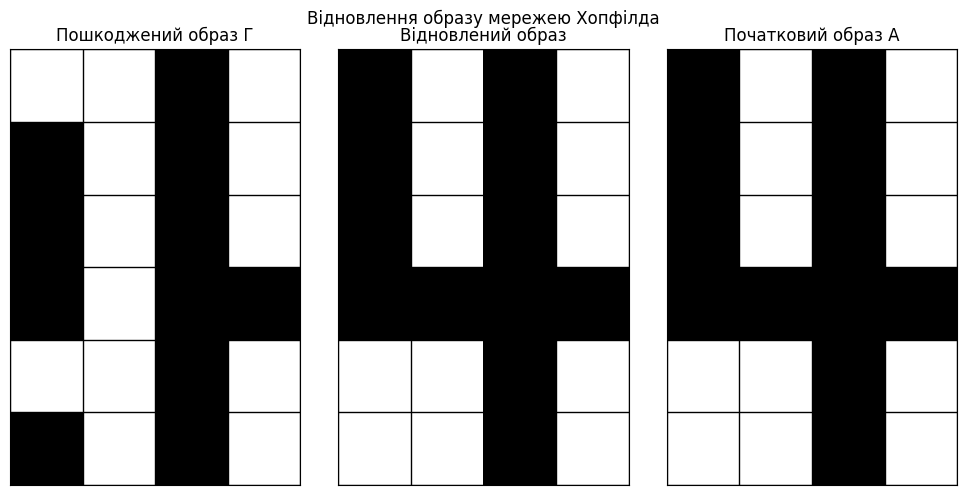

In [7]:

# Перетворюємо зображення Г у біполярний вектор
state = G.flatten() * 2 - 1

print("Початковий образ Г:")
print(G)

# Відновлення образу мережею Хопфілда
max_iterations = 20

for iteration in range(max_iterations):
    old_state = state.copy()

    # Послідовне оновлення станів нейронів
    for i in range(24):
        activation = np.dot(W_hopfield[i], state)

        if activation > 0:
            state[i] = 1
        elif activation < 0:
            state[i] = -1

    changes = np.sum(old_state != state)

    print(f"Ітерація {iteration+1}: "
          f"змінено клітинок = {changes}")

    # Зупинка після стабілізації
    if changes == 0:
        break

# Перетворення результату назад у зображення
restored = ((state + 1) // 2).reshape(6, 4)

print("\nВідновлене зображення:")
print(restored)

print("\nЧи збігається результат із образом А?")
print(np.array_equal(restored, A))

# Візуалізація результатів
images = [G, restored, A]
titles = [
    "Пошкоджений образ Г",
    "Відновлений образ",
    "Початковий образ А"
]

fig, axes = plt.subplots(1, 3, figsize=(10, 5))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="Greys", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 6, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=1)
    ax.tick_params(which="minor", length=0)

plt.suptitle("Відновлення образу мережею Хопфілда")
plt.tight_layout()
plt.show()
